In [3]:
# Survival Analytics - Kaplan-Meier and Cox Proportional Hazards
# Datasets:
#   - Telco Customer Churn (Kaggle): ../Datasets/WA_Fn-UseC_-Telco-Customer-Churn.csv
#     https://www.kaggle.com/datasets/blastchar/telco-customer-churn
#   - Rossi recidivism + Lung cancer: built into the lifelines package
#
# Needs: pip install lifelines
#
# Survival analysis vocabulary (worth memorising):
#   duration = how long until the event happened OR until we stopped watching
#   event    = 1 if the event actually happened, 0 if the person was "censored"
#              (still around when the data ended, so we don't know their real end)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test
from lifelines.datasets import load_rossi, load_lung

(7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Co

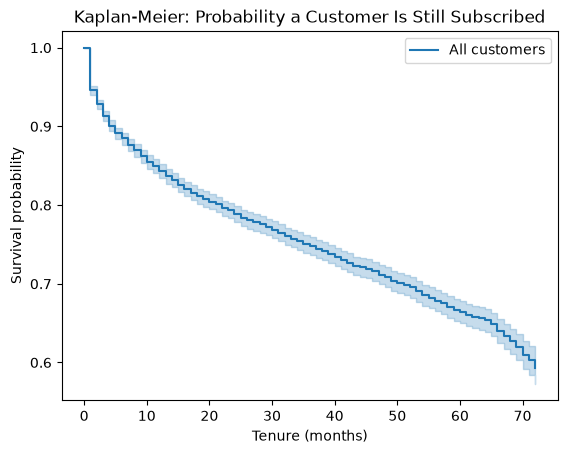

Median survival time (months): inf


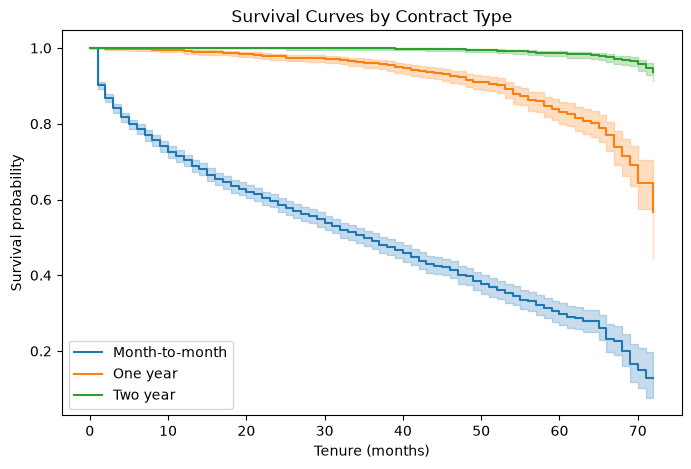

Log-rank p-value: 0.0


<lifelines.CoxPHFitter: fitted with 7032 total observations, 5163 right-censored observations>
             duration col = 'tenure'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 7032
number of events observed = 1869
   partial log-likelihood = -14251.62
         time fit was run = 2026-09-28 11:03:27 UTC

---
                  coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                         
MonthlyCharges    0.00      1.00      0.00           -0.00            0.00                1.00                1.00
SeniorCitizen     0.03      1.03      0.06           -0.08            0.14                0.92                1.15
Contract_OneYear -2.11      0.12      0.08           -2.27           -1.94                0.10                0.14
Contract_TwoYear -4.06      0.02      0.16           -4.38           -3.75                0.01                0.02
PaperlessBilling  0.24      1.27      0.06            0.13            0.35                1.14                1.42
Partner          -0.63      0.54      0.05           -0.72           -0.53                0.49                0.59

                  cmp to      z      p  -log2(p)
covariate                                       
MonthlyCharges      0.00   0.01   0.99      0.02
SeniorCitizen       0.00   0.52   0.61      0.72
Contract_OneYear    0.00 -24.94 <0.005    453.70
Contract_TwoYear    0.00 -25.62 <0.005    478.58
PaperlessBilling    0.00   4.22 <0.005     15.34
Partner             0.00 -12.51 <0.005    116.96
---
Concordance = 0.81
Partial AIC = 28515.23
log-likelihood ratio test = 2802.84 on 6 df
-log2(p) of ll-ratio test = inf

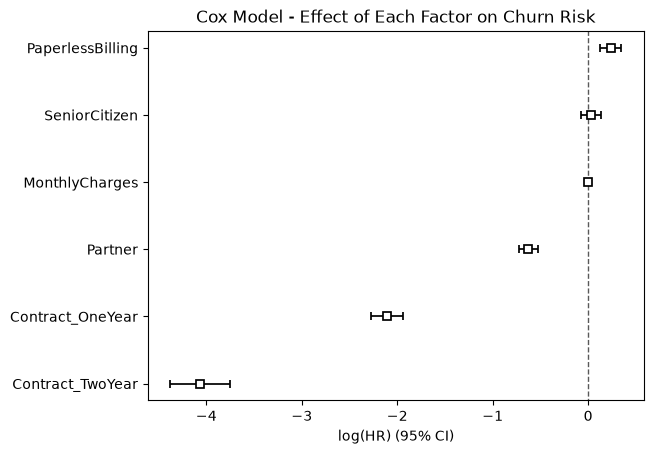

                  exp(coef)      p
covariate                         
MonthlyCharges        1.000  0.989
SeniorCitizen         1.029  0.606
Contract_OneYear      0.122  0.000
Contract_TwoYear      0.017  0.000
PaperlessBilling      1.268  0.000
Partner               0.535  0.000


In [4]:
# ============================================================
# PART 1 - Telco Customer Churn (time-to-churn)
# ============================================================

#df = pd.read_csv("../Datasets/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = pd.read_csv(r"C:\Users\syin\Downloads\archive (42)\WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
print(df.head())

# ---- 1. Clean the data ----
# TotalCharges is stored as text because a few rows have blank spaces
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isnull().sum(), "blank TotalCharges rows")

# those blank rows are brand-new customers with tenure = 0 - no observation time yet,
# so they can't contribute anything to a survival analysis. Drop them.
df = df[df["tenure"] > 0].copy()

# ---- 2. Define duration and event ----
# duration = tenure (months the customer stayed)
# event    = 1 if they churned, 0 if still a customer (censored)
df["event"] = (df["Churn"] == "Yes").astype(int)

print(df["event"].value_counts())
print("Churn rate:", df["event"].mean().round(3))

# ---- 3. Kaplan-Meier curve for ALL customers ----
kmf = KaplanMeierFitter()
kmf.fit(durations=df["tenure"], event_observed=df["event"], label="All customers")
kmf.plot_survival_function()
plt.title("Kaplan-Meier: Probability a Customer Is Still Subscribed")
plt.xlabel("Tenure (months)")
plt.ylabel("Survival probability")
plt.show()

print("Median survival time (months):", kmf.median_survival_time_)
# if this prints inf, more than half the customers never churned during the data window

# ---- 4. Compare groups - month-to-month vs long contracts ----
plt.figure(figsize=(8, 5))
ax = plt.subplot(111)

for contract in df["Contract"].unique():
    mask = df["Contract"] == contract
    kmf_c = KaplanMeierFitter()
    kmf_c.fit(df.loc[mask, "tenure"], df.loc[mask, "event"], label=contract)
    kmf_c.plot_survival_function(ax=ax)

plt.title("Survival Curves by Contract Type")
plt.xlabel("Tenure (months)")
plt.ylabel("Survival probability")
plt.show()

# month-to-month customers drop off much faster than one/two year contracts

# ---- 5. Log-rank test - is the difference statistically real? ----
m2m = df[df["Contract"] == "Month-to-month"]
two_year = df[df["Contract"] == "Two year"]

result = logrank_test(
    m2m["tenure"], two_year["tenure"],
    event_observed_A=m2m["event"], event_observed_B=two_year["event"]
)
print("Log-rank p-value:", result.p_value)
# p < 0.05 -> the two survival curves are significantly different

# ---- 6. Cox Proportional Hazards - which factors affect churn risk? ----
# Cox needs numeric columns only, so pick a few and encode them
cox_df = df[["tenure", "event", "MonthlyCharges", "SeniorCitizen"]].copy()
cox_df["Contract_OneYear"] = (df["Contract"] == "One year").astype(int)
cox_df["Contract_TwoYear"] = (df["Contract"] == "Two year").astype(int)
cox_df["PaperlessBilling"] = (df["PaperlessBilling"] == "Yes").astype(int)
cox_df["Partner"] = (df["Partner"] == "Yes").astype(int)

cph = CoxPHFitter()
cph.fit(cox_df, duration_col="tenure", event_col="event")

cph.print_summary()

cph.plot()
plt.title("Cox Model - Effect of Each Factor on Churn Risk")
plt.show()

# reading the results:
#   exp(coef) > 1 -> factor INCREASES churn risk (hazard)
#   exp(coef) < 1 -> factor DECREASES churn risk
# e.g. Contract_TwoYear should have exp(coef) far below 1 (much lower churn hazard)

print(cph.summary[["exp(coef)", "p"]].round(3))


   week  arrest  fin  age  race  wexp  mar  paro  prio
0    20       1    0   27     1     0    0     1     3
1    17       1    0   18     1     0    0     1     8
2    25       1    0   19     0     1    0     1    13
3    52       0    1   23     1     1    1     1     1
4    52       0    0   19     0     1    0     1     3


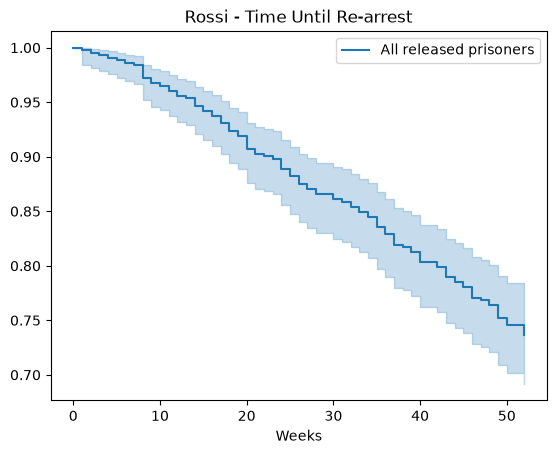

<lifelines.CoxPHFitter: fitted with 432 total observations, 318 right-censored observations>
             duration col = 'week'
                event col = 'arrest'
      baseline estimation = breslow
   number of observations = 432
number of events observed = 114
   partial log-likelihood = -658.75
         time fit was run = 2026-09-28 11:03:31 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
fin       -0.38      0.68      0.19           -0.75           -0.00                0.47                1.00
age       -0.06      0.94      0.02           -0.10           -0.01                0.90                0.99
race       0.31      1.37      0.31           -0.29            0.92                0.75                2.50
wexp      -0.15      0.86      0.21           -0.57            0.27                0.57                1.30
mar       -0.43      0.65      0.38           -1.18            0.31                0.31                1.37
paro      -0.08      0.92      0.20           -0.47            0.30                0.63                1.35
prio       0.09      1.10      0.03            0.04            0.15                1.04                1.16

           cmp to     z      p  -log2(p)
covariate                               
fin          0.00 -1.98   0.05      4.40
age          0.00 -2.61   0.01      6.79
race         0.00  1.02   0.31      1.70
wexp         0.00 -0.71   0.48      1.06
mar          0.00 -1.14   0.26      1.97
paro         0.00 -0.43   0.66      0.59
prio         0.00  3.19 <0.005      9.48
---
Concordance = 0.64
Partial AIC = 1331.50
log-likelihood ratio test = 33.27 on 7 df
-log2(p) of ll-ratio test = 15.37

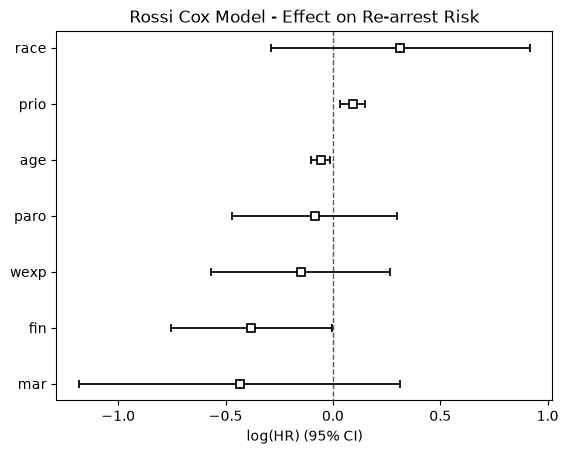

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'age' failed the non-proportional test: p-value is 0.0007.

   Advice 1: the functional form of the variable 'age' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'age' using pd.cut, and then specify it in `strata=['age',
...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'wexp' failed the non-proportional test: p-value is 0.0063.

   Advice: with so few unique values (only 2), you can include `strata=['wexp', ...]` in the call in
`.fit`. See documentation in link [E] below.

---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/lat

[]

In [5]:
# ============================================================
# PART 2 - Rossi recidivism dataset (lifelines built-in)
# ============================================================
# NOTE: Rossi is NOT a cancer dataset - it tracks 432 men released from prison and
# how many weeks until they were re-arrested. It's the standard teaching
# dataset for Cox regression.

rossi = load_rossi()
print(rossi.head())
# week   = weeks until re-arrest (or until follow-up ended)
# arrest = 1 if re-arrested, 0 if censored (not re-arrested by end of study)
# fin    = 1 if received financial aid after release
# age, race, wexp (work experience), mar (married), paro (paroled), prio (prior convictions)

kmf_r = KaplanMeierFitter()
kmf_r.fit(rossi["week"], rossi["arrest"], label="All released prisoners")
kmf_r.plot_survival_function()
plt.title("Rossi - Time Until Re-arrest")
plt.xlabel("Weeks")
plt.show()

# ---- Cox regression on Rossi ----
cph_r = CoxPHFitter()
cph_r.fit(rossi, duration_col="week", event_col="arrest")
cph_r.print_summary()

cph_r.plot()
plt.title("Rossi Cox Model - Effect on Re-arrest Risk")
plt.show()

# ---- Check the proportional hazards assumption ----
# Cox regression assumes each factor's effect stays constant over time
cph_r.check_assumptions(rossi, p_value_threshold=0.05, show_plots=False)


   inst  time  status  age  sex  ph.ecog  ph.karno  pat.karno  meal.cal  \
0   3.0   306       1   74    1      1.0      90.0      100.0    1175.0   
1   3.0   455       1   68    1      0.0      90.0       90.0    1225.0   
2   3.0  1010       0   56    1      0.0      90.0       90.0       NaN   
3   5.0   210       1   57    1      1.0      90.0       60.0    1150.0   
4   1.0   883       1   60    1      0.0     100.0       90.0       NaN   

   wt.loss  
0      NaN  
1     15.0  
2     15.0  
3     11.0  
4      0.0  
inst          1
time          0
status        0
age           0
sex           0
ph.ecog       1
ph.karno      1
pat.karno     3
meal.cal     47
wt.loss      14
dtype: int64


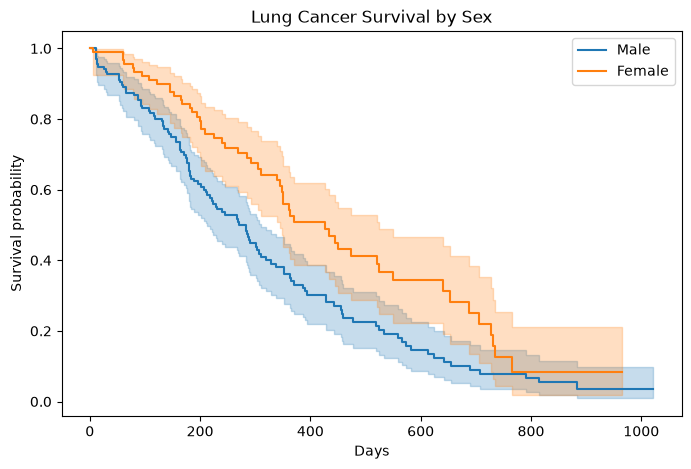

<lifelines.CoxPHFitter: fitted with 226 total observations, 63 right-censored observations>
             duration col = 'time'
                event col = 'status'
      baseline estimation = breslow
   number of observations = 226
number of events observed = 163
   partial log-likelihood = -723.42
         time fit was run = 2026-09-28 11:03:35 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
age        0.01      1.01      0.01           -0.01            0.03                0.99                1.03
sex       -0.57      0.56      0.17           -0.90           -0.24                0.40                0.79
ph.ecog    0.63      1.88      0.18            0.29            0.98                1.33                2.66
ph.karno   0.01      1.01      0.01           -0.01            0.03                0.99                1.03

           cmp to     z      p  -log2(p)
covariate                               
age          0.00  1.37   0.17      2.55
sex          0.00 -3.38 <0.005     10.46
ph.ecog      0.00  3.60 <0.005     11.60
ph.karno     0.00  1.32   0.19      2.42
---
Concordance = 0.63
Partial AIC = 1454.85
log-likelihood ratio test = 31.27 on 4 df
-log2(p) of ll-ratio test = 18.50

In [6]:
# ============================================================
# PART 3 - Lung cancer dataset (lifelines built-in, load_lung)
# ============================================================
# This is the real cancer survival dataset: patients with advanced lung cancer.
# time = survival time in days, status = 1 if died, 0 if censored

lung = load_lung()
print(lung.head())
print(lung.isnull().sum())

# keep a few columns and drop rows with missing values (small amount here)
lung_df = lung[["time", "status", "age", "sex", "ph.ecog", "ph.karno"]].dropna()

kmf_l = KaplanMeierFitter()

plt.figure(figsize=(8, 5))
ax = plt.subplot(111)
# sex is coded 1 = male, 2 = female in this dataset
for sex_code, label in [(1, "Male"), (2, "Female")]:
    mask = lung_df["sex"] == sex_code
    kmf_l.fit(lung_df.loc[mask, "time"], lung_df.loc[mask, "status"], label=label)
    kmf_l.plot_survival_function(ax=ax)

plt.title("Lung Cancer Survival by Sex")
plt.xlabel("Days")
plt.ylabel("Survival probability")
plt.show()

cph_l = CoxPHFitter()
cph_l.fit(lung_df, duration_col="time", event_col="status")
cph_l.print_summary()